# Time Series 2016 to 2026

The model is applied to one scene per year, so the growth of the solar park can be followed year by year. Every year goes through exactly the same steps as the 2026 scene in notebook 04, so the numbers are comparable.

For each year: pick a cloud-free scene from the same season as the training data, prepare it, predict, and measure the PV area. The hand labels of 2020 and 2026 serve as control points for the two ends of the series.

## Setup

In [33]:
import sys
from pathlib import Path

import geoai
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio

sys.path.append("../scripts")
from preprocessing import BASELINE_OFFSET, scale_to_byte
from scene_search import TALATAN_BBOX, download_scene, search_scenes

BASE_DIR = Path().resolve().parent if Path().resolve().name == "notebooks" else Path().resolve()
DATA_DIR = BASE_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
SCENE_DIR = RAW_DIR / "raster" / "sentinel2"
SCALED_DIR = DATA_DIR / "processed" / "scaled"
MODEL_DIR = BASE_DIR / "models"
PREDICTIONS_DIR = BASE_DIR / "results" / "predictions"
EVALUATION_DIR = BASE_DIR / "results" / "evaluation"
FIGURES_DIR = BASE_DIR / "results" / "figures"

YEARS = list(range(2016, 2027))  # 2016 is the first full season of Sentinel-2; the model was trained on 2020
SEASON = "08-15", "10-31"        # same season as the training scenes
MAX_CLOUD = 10                   # maximum mean cloud cover of a day, in percent

# Days picked by visual inspection instead of the automatic choice. The tile-wide
# cloud cover in the metadata does not say how clear the park itself is.
# 2016-10-18 shows the park more clearly than the automatic pick 2016-10-15.
# 2022-09-29, 2025-10-13 and 2026-10-03 replace the automatic picks (2022-10-17,
# 2025-10-18, 2026-10-06), on which the model maps less area than in the year before
# or misses parts of the park. The test scene in notebooks 04 and 06 stays 2026-10-06.
SCENE_OVERRIDES = {
    2016: "2016-10-18",
    2022: "2022-09-29",
    2025: "2025-10-13",
    2026: "2026-10-03",
}

MODEL_FILE = "talatan_unet.pth"
NUM_CHANNELS = 4

# Hand-labelled scenes, used as control points
CONTROL_DAYS = ["2020-12-23", "2026-10-06"]

for folder in (SCENE_DIR, SCALED_DIR, PREDICTIONS_DIR, EVALUATION_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

## Scene Selection

One scene per year: among the days that cover the whole study area, the one with the lowest cloud cover is taken. Restricting the search to late summer and early autumn keeps the illumination close to the training scenes, which matters because the model reacts to how the modules look. For years listed in `SCENE_OVERRIDES`, the day was chosen by visual inspection instead.


In [34]:
scene_days = {}

for year in YEARS:
    candidates = search_scenes(
        TALATAN_BBOX,
        f"{year}-{SEASON[0]}",
        f"{year}-{SEASON[1]}",
        max_cloud=MAX_CLOUD,
    )

    if year in SCENE_OVERRIDES:
        # Search the chosen day alone, without the cloud pre-filter
        day = SCENE_OVERRIDES[year]
        chosen = search_scenes(TALATAN_BBOX, day, day, max_cloud=100)
        if not chosen:
            raise ValueError(f"{year}: no full-coverage scene on {day}")
        best = chosen[0]
        source = "manual"
    elif candidates:
        best = candidates[0]   # search_scenes sorts by cloud cover, lowest first
        source = "auto"
    else:
        print(f"{year}: no day with full coverage below {MAX_CLOUD} % clouds")
        continue

    scene_days[year] = best
    baseline = best["items"][0].properties.get("s2:processing_baseline", "?")
    print(f"{year}: {best['day']} ({source}) | clouds: {best['clouds']:4.1f} % | baseline {baseline} | {len(candidates)} candidate days")

2016: 2016-10-18 (manual) | clouds:  2.2 % | baseline 02.12 | 3 candidate days
2017: 2017-09-10 (auto) | clouds:  0.7 % | baseline 02.12 | 3 candidate days
2018: 2018-10-28 (auto) | clouds:  1.0 % | baseline 02.12 | 5 candidate days
2019: 2019-10-23 (auto) | clouds:  2.0 % | baseline 02.12 | 1 candidate days
2020: 2020-08-20 (auto) | clouds:  0.6 % | baseline 02.12 | 8 candidate days
2021: 2021-09-07 (auto) | clouds:  3.0 % | baseline 03.00 | 3 candidate days
2022: 2022-09-29 (manual) | clouds:  6.9 % | baseline 05.10 | 4 candidate days
2023: 2023-10-19 (auto) | clouds:  0.1 % | baseline 05.09 | 9 candidate days
2024: 2024-10-13 (auto) | clouds:  0.0 % | baseline 05.11 | 9 candidate days
2025: 2025-10-13 (manual) | clouds:  0.0 % | baseline 05.11 | 14 candidate days
2026: 2026-10-03 (manual) | clouds:  2.5 % | baseline 05.13 | 12 candidate days


## Download and Preparation

Each scene is loaded on the same grid as the training data and then prepared as in notebook 04: the baseline offset of 1000 is subtracted for scenes from 2022 onwards, and the reflectance is mapped from 0-4000 to 0-255. Scenes that are already on disk are not downloaded again.

In [35]:
scenes = {}

for year, best in scene_days.items():
    day = best["day"]
    raw_scene = download_scene(best["items"], TALATAN_BBOX, SCENE_DIR / f"talatan_{day}.tif")

    # The offset was introduced with processing baseline 04.00 in January 2022
    offset = BASELINE_OFFSET if day.year >= 2022 else 0
    scene = scale_to_byte(raw_scene, SCALED_DIR / f"talatan_{day}_scaled.tif", offset=offset)

    scenes[year] = {"day": day, "raw": raw_scene, "scene": scene, "offset": offset}
    print(f"{year}: {day} ready (offset {offset})")

2016: 2016-10-18 ready (offset 0)
2017: 2017-09-10 ready (offset 0)
2018: 2018-10-28 ready (offset 0)
2019: 2019-10-23 ready (offset 0)
2020: 2020-08-20 ready (offset 0)
2021: 2021-09-07 ready (offset 0)
2022: 2022-09-29 ready (offset 1000)
2023: 2023-10-19 ready (offset 1000)
2024: 2024-10-13 ready (offset 1000)
2025: 2025-10-13 ready (offset 1000)
2026: 2026-10-03 ready (offset 1000)


## Prediction

The same model and the same settings for every year. The area is read from the predicted mask; no threshold other than the default 0.5 is applied.

In [36]:
rows = []

for year, info in scenes.items():
    day = info["day"]
    mask_path = PREDICTIONS_DIR / f"prediction_{day}.tif"

    geoai.semantic_segmentation(
        input_path=str(info["scene"]),
        output_path=str(mask_path),
        model_path=str(MODEL_DIR / MODEL_FILE),
        architecture="unet",
        encoder_name="resnet34",
        num_channels=NUM_CHANNELS,
        num_classes=2,
        window_size=384,
        overlap=192,
        batch_size=4,
    )

    with rasterio.open(mask_path) as src:
        predicted = src.read(1) == 1
        pixel_area = abs(src.transform.a * src.transform.e)
        grid_shape, grid_transform, grid_crs = src.shape, src.transform, src.crs

    info["mask_path"] = mask_path
    rows.append({"year": year, "date": day, "predicted_km2": predicted.sum() * pixel_area / 1e6})
    print(f"{year}: {rows[-1]['predicted_km2']:6.1f} km²")

series = pd.DataFrame(rows).set_index("year")


  0%|          | 0/525 [00:00<?, ?it/s]

2016:   66.0 km²


  0%|          | 0/525 [00:00<?, ?it/s]

2017:   72.3 km²


  0%|          | 0/525 [00:00<?, ?it/s]

2018:   92.3 km²


... (12 outputs left out)

  0%|          | 0/525 [00:00<?, ?it/s]

2025:  340.9 km²


  0%|          | 0/525 [00:00<?, ?it/s]

2026:  346.0 km²


## Control Points

The two hand-labelled scenes give the area independently of the model. The labels are not from the same day as the yearly scene: 2020-12-23 against 2020-08-20, and 2026-10-06 against 2026-10-03. The difference between the two columns is therefore the error of the method plus any construction between the two dates. For 2020 the gap is four months, during which the park grew, which explains part of the lower predicted value.

In [37]:
def label_area(day):
    polygons = gpd.read_file(RAW_DIR / "vectors" / f"own_labels_{day}.shp").to_crs(grid_crs)
    polygons["geometry"] = polygons.geometry.make_valid()
    return polygons.union_all().area / 1e6


series["labelled_km2"] = np.nan
for day in CONTROL_DAYS:
    year = int(day[:4])
    if year in series.index:
        series.loc[year, "labelled_km2"] = label_area(day)

series["difference_km2"] = series["predicted_km2"] - series["labelled_km2"]
series["growth_km2"] = series["predicted_km2"].diff()

series.round(1).to_csv(EVALUATION_DIR / "area_time_series.csv")
series.round(1)


,date,predicted_km2,labelled_km2,difference_km2,growth_km2
year,,,,,
2016,2016-10-18,66.0,NaN,NaN,NaN
2017,2017-09-10,72.3,NaN,NaN,6.3
2018,2018-10-28,92.3,NaN,NaN,20.1
2019,2019-10-23,99.2,NaN,NaN,6.9
2020,2020-08-20,133.1,144.8,-11.7,33.9
2021,2021-09-07,168.0,NaN,NaN,34.9
2022,2022-09-29,173.3,NaN,NaN,5.3
2023,2023-10-19,249.5,NaN,NaN,76.2
2024,2024-10-13,300.4,NaN,NaN,50.9


## Area Curve

The predicted area per year, with the hand-labelled areas as control points.

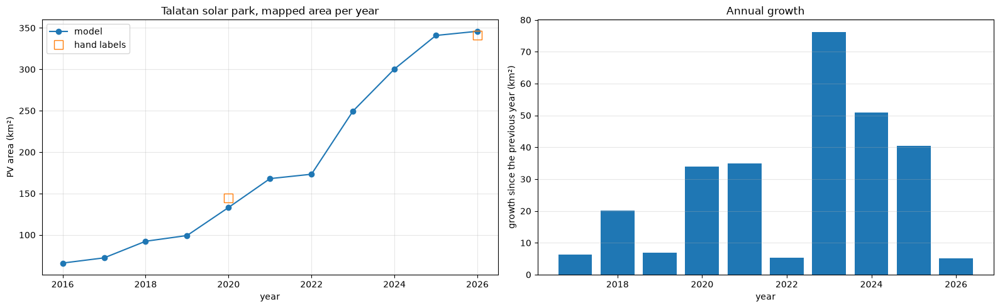

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(series.index, series["predicted_km2"], marker="o", label="model")
axes[0].plot(series.index, series["labelled_km2"], marker="s", linestyle="none",
             markersize=10, markerfacecolor="none", label="hand labels")
axes[0].set_ylabel("PV area (km²)")
axes[0].set_title("Talatan solar park, mapped area per year")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].bar(series.index[1:], series["growth_km2"][1:])
axes[1].set_ylabel("growth since the previous year (km²)")
axes[1].set_title("Annual growth")
axes[1].grid(alpha=0.3, axis="y")

for ax in axes:
    ax.set_xlabel("year")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "area_time_series.png", dpi=150, bbox_inches="tight")
plt.show()


## Maps per Year

The predicted PV area of every year on top of its own scene. Read as a sequence, the panels show where the park grew.

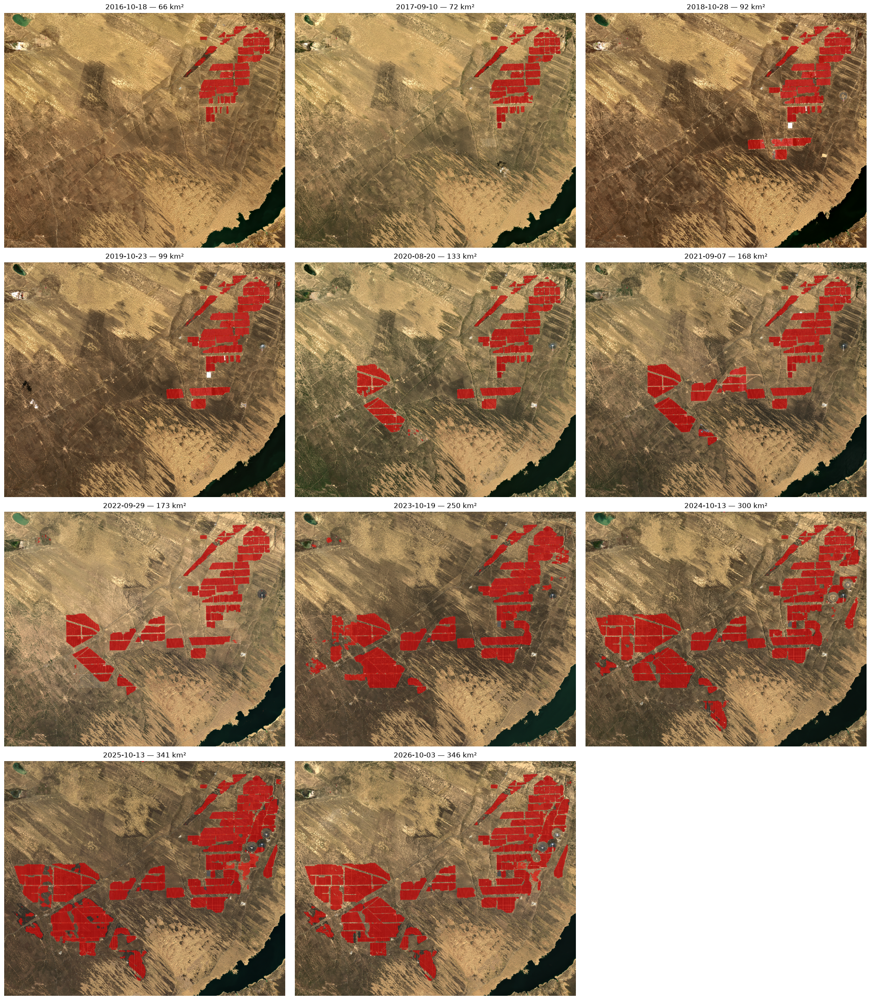

In [39]:
F = 6   # downsampling for display only

n_cols = 3
n_rows = int(np.ceil(len(scenes) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(7 * n_cols, 6 * n_rows), squeeze=False)

for ax in axes.flat:
    ax.axis("off")

for ax, (year, info) in zip(axes.flat, scenes.items()):
    with rasterio.open(info["scene"]) as src:
        small_shape = (src.height // F, src.width // F)
        rgb = src.read([3, 2, 1], out_shape=(3, *small_shape))
    rgb = np.clip(np.moveaxis(rgb, 0, -1) / 191, 0, 1)   # 191 = reflectance 3000 after scaling

    with rasterio.open(info["mask_path"]) as src:
        small_mask = src.read(1, out_shape=small_shape) == 1

    overlay = rgb.copy()
    overlay[small_mask] = 0.45 * overlay[small_mask] + 0.55 * np.array([1.0, 0.0, 0.0])

    ax.imshow(overlay)
    ax.set_title(f"{info['day']} — {series.loc[year, 'predicted_km2']:.0f} km²")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "maps_per_year.png", dpi=150, bbox_inches="tight")
plt.show()


## Where the Park Grew

The first and the last year side by side, and a map of the difference: areas that are PV in the last year but were not in the first one.

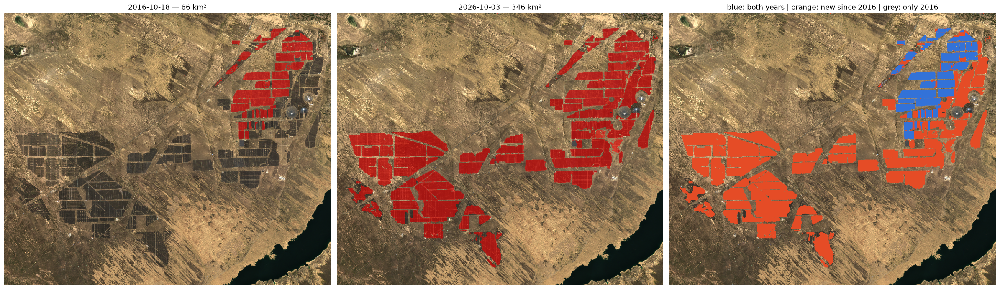

New PV area between 2016 and 2026: 280.9 km²


In [40]:
first_year, last_year = min(scenes), max(scenes)

with rasterio.open(scenes[last_year]["scene"]) as src:
    small_shape = (src.height // F, src.width // F)
    rgb = src.read([3, 2, 1], out_shape=(3, *small_shape))
rgb = np.clip(np.moveaxis(rgb, 0, -1) / 191, 0, 1)

# The masks are read at exactly the shape of the image above. Slicing them with
# [::F, ::F] instead would round the other way and give one row too many.
masks = {}
for year in (first_year, last_year):
    with rasterio.open(scenes[year]["mask_path"]) as src:
        masks[year] = src.read(1, out_shape=small_shape) == 1

added = masks[last_year] & ~masks[first_year]
removed = masks[first_year] & ~masks[last_year]

change = rgb.copy()
change[masks[first_year] & masks[last_year]] = [0.20, 0.45, 0.85]   # present in both years
change[added] = [0.90, 0.30, 0.15]                                  # new since the first year
change[removed] = [0.55, 0.55, 0.55]                                # only in the first year

fig, axes = plt.subplots(1, 3, figsize=(24, 8))

for ax, year in zip(axes[:2], (first_year, last_year)):
    overlay = rgb.copy()
    overlay[masks[year]] = 0.45 * overlay[masks[year]] + 0.55 * np.array([1.0, 0.0, 0.0])
    ax.imshow(overlay)
    ax.set_title(f"{scenes[year]['day']} — {series.loc[year, 'predicted_km2']:.0f} km²")

axes[2].imshow(change)
axes[2].set_title(f"blue: both years | orange: new since {first_year} | grey: only {first_year}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "growth_map.png", dpi=150, bbox_inches="tight")
plt.show()

pixel_area_small = pixel_area * F * F
print(f"New PV area between {first_year} and {last_year}: {added.sum() * pixel_area_small / 1e6:.1f} km²")


## Year Slider

The same panels as above, but one at a time: drag the slider to step through the years and watch the red area grow. The previews are prepared once, so moving the slider is immediate.

Saved: growth_animation.gif


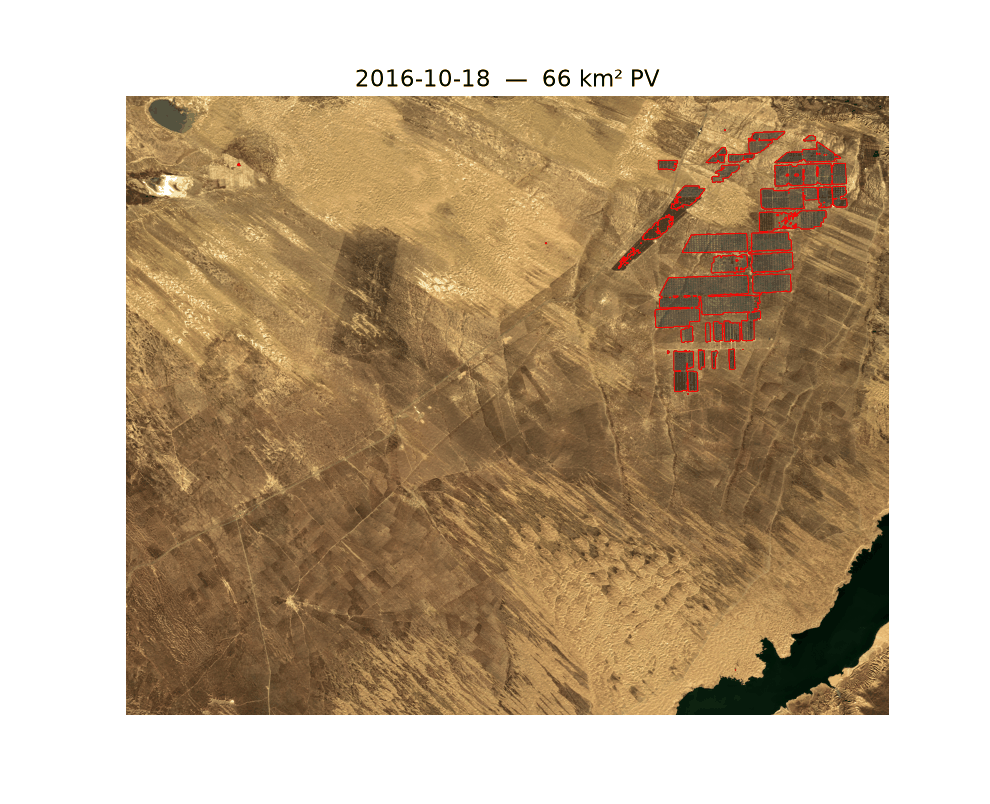

In [41]:
import io

from IPython.display import Image, display
from matplotlib.colors import ListedColormap
from matplotlib.figure import Figure
from PIL import Image as PILImage
from rasterio.windows import Window

FRAME_SECONDS = 2   # how long each year stays on screen
LAST_FRAME_HOLD = 3   # the final year stays this many times longer
F_ANIM = 2            # 20 m display pixels: fine enough to see the panel fields
MARGIN_M = 1500       # margin around the park, in metres
FILL_ALPHA = 0.    # transparency of the red fill; the outline stays fully visible

# Crop to the park: extent of the largest predicted mask plus a margin, same for all years
largest_year = series["predicted_km2"].idxmax()
with rasterio.open(scenes[largest_year]["mask_path"]) as src:
    rows, cols = np.nonzero(src.read(1) == 1)
    pad = int(MARGIN_M / src.res[0])
    window = Window.from_slices(
        (max(rows.min() - pad, 0), min(rows.max() + pad, src.height)),
        (max(cols.min() - pad, 0), min(cols.max() + pad, src.width)),
    )
crop_shape = (int(window.height) // F_ANIM, int(window.width) // F_ANIM)
figsize = (9, 9 * crop_shape[0] / crop_shape[1])
red = ListedColormap(["red"])


def render_year(year):
    """Render one year as an image frame: the scene, a light red fill and a red outline."""
    info = scenes[year]
    with rasterio.open(info["scene"]) as src:
        rgb = src.read([3, 2, 1], window=window, out_shape=(3, *crop_shape))
    rgb = np.clip(np.moveaxis(rgb, 0, -1) / 191, 0, 1)

    with rasterio.open(info["mask_path"]) as src:
        mask = src.read(1, window=window, out_shape=crop_shape) == 1

    fig = Figure(figsize=figsize)
    ax = fig.subplots()
    ax.imshow(rgb)
    ax.imshow(np.ma.masked_where(~mask, np.ones(mask.shape)), cmap=red, alpha=FILL_ALPHA, interpolation="nearest")
    ax.contour(mask.astype(np.uint8), levels=[0.5], colors="red", linewidths=0.7)
    ax.set_title(f"{info['day']}  —  {series.loc[year, 'predicted_km2']:.0f} km² PV", fontsize=15)
    ax.axis("off")

    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=110)   # no tight bbox: all frames must have the same size
    buffer.seek(0)
    return PILImage.open(buffer).convert("RGB")


frames = [render_year(year) for year in sorted(scenes)]
durations = [int(FRAME_SECONDS * 1000)] * len(frames)
durations[-1] *= LAST_FRAME_HOLD

gif_path = FIGURES_DIR / "growth_animation.gif"
frames[0].save(gif_path, save_all=True, append_images=frames[1:], duration=durations, loop=0)
print(f"Saved: {gif_path.name}")

display(Image(filename=str(gif_path)))